</br>
<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>Práctica 2:
        </h2>
        <h1 style="margin-top: -10px;">
            Aprendizaje y selección de modelos de clasificación
        </h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Minería de Datos, 2026-27
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="font-size: 1em; color: #D0D0D0;">
                        José Antonio Gámez Martín
                    </span>
                    <a href="mailto:Jose.Gamez@uclm.es" style="text-decoration: none; color: #888888; font-size: 0.8em; padding-left: 15px;">
                        ✉ Jose.Gamez@uclm.es
                    </a>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="font-size: 1em; color: #D0D0D0;">
                        Pablo Torrijos Arenas
                    </span>
                    <a href="mailto:Pablo.Torrijos@uclm.es" style="text-decoration: none; color: #888888; font-size: 0.8em; padding-left: 15px;">
                        ✉ Pablo.Torrijos@uclm.es
                    </a>
                </div>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Estudiantes
        </h3>
    </div>
    <ul style="list-style-type: none; padding-left: 28px; margin: 0;  font-size: 1.1em">
        <li>Alfredo Solis Ortiz</li>
    </ul>

</div>

## 1. Introducción

El objetivo de esta práctica es construir sobre el trabajo realizado en la Práctica 1. Se aplicarán y compararán diversos modelos de clasificación supervisada, utilizando validación cruzada y ajuste de hiperparámetros, para seleccionar el modelo más eficaz en la predicción del abandono estudiantil.

Para ello, continuaréis utilizando los mismos conjuntos de datos de la práctica anterior (`uclm_student_train.csv` y `uclm_student_test.csv`). El `Pipeline` de preprocesamiento desarrollado en la Práctica 1 servirá como base para el entrenamiento de los modelos (aunque podéis modificarlo, y lo normal es que lo hagáis a medida que entendáis mejor los datos).

Tendréis que explorar y evaluar los modelos de clasificación introducidos en el notebook complementario (`Material Práctica 2 - Selección de modelos.ipynb`), junto con al menos un algoritmo adicional investigado de forma independiente, el cual tendréis que explicar más detalladamente. El rendimiento se evaluará rigurosamente mediante validación cruzada, y técnicas como `GridSearchCV` para encontrar la configuración óptima de hiperparámetros.

El modelo final seleccionado se utilizará para generar predicciones en el conjunto de prueba y participar en la competición de Kaggle.

### 1.1. Requisitos

* **Modelos**: evaluar los modelos del notebook complementario y **al menos uno más** investigado por vuestra cuenta, explicando cómo funciona y qué hiperparámetros tiene.
* **Búsqueda de hiperparámetros**: usar `GridSearchCV` (o alguna de sus alternativas) sobre el `Pipeline` completo, nunca sobre los datos ya preprocesados.
* **Validación**: justificar el esquema de validación cruzada elegido. No todos los problemas admiten una partición aleatoria, y conviene comprobar si vuestros datos tienen alguna estructura que la partición deba respetar.
* **Métrica**: la competición puntúa el **F1-Score** sobre la clase `abandono = 1`, así que esa es la métrica que hay que optimizar. No obstante, se valorará el estudio de más métricas para entender el comportamiento del modelo.
* **Coherencia entre validación y Kaggle**: si vuestra estimación de validación cruzada y la puntuación del *leaderboard* se separan mucho, investigad a qué se debe y comentadlo en la memoria.
* **Entrega a Kaggle**: se valorará en esta práctica.

### 1.2. Recordatorio: competición en Kaggle

La evaluación final se realizará mediante una competición privada en Kaggle. El objetivo es maximizar la métrica **F1-Score**, una medida robusta que tiene en cuenta tanto la precisión como la exhaustividad, especialmente útil en casos con clases desbalanceadas.

* **Enlace a la competición**: [https://www.kaggle.com/t/ac5493e898134a3bb6013c786b2d09a8](https://www.kaggle.com/t/ac5493e898134a3bb6013c786b2d09a8)

Los equipos con mejor rendimiento en el *private leaderboard* recibirán una bonificación en la nota final:
* **1er puesto**: +0.75 puntos.
* **2º puesto**: +0.5 puntos.
* **3er puesto**: +0.25 puntos.

**Nota**: Las bonificaciones están sujetas a la revisión del código y la metodología. Se podrá requerir una justificación del enfoque para verificar la originalidad y la comprensión del trabajo.

<div style="border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: 10px"></div>

## 2. Carga de Datos y Preprocesamiento Base




Como punto de partida, cargaremos los datos igual que en la Práctica 1:

In [20]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

df_train = pd.read_csv('uclm_student_train.csv')
df_train

,id,nombre,nacimiento,provincia,residencia_id,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,modalidad,creditos_a1,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,numero_fav,talla_zapato,color_fav,meses_matriculado,grupo_trabajo,abandono
0,CR-2018-BCG465,Berta Calderon Giménez,1995-12-02,Albacete,E1-P00-H12,Bellas Artes,Ciclo Formativo de Grado Superior,"7,09",SOCIAL,0,NaN,Tiempo completo,60,60,"8,57","4,15",~5.5 horas,3,0,2,NaN,46,40,Beige pálido,12,GR007497,0
1,TO-2014-CFB931,Celestina Font Barranco,1996-02-25,Ciudad Real,E1-P02-H17,Doble Grado Derecho-ade,PAU / Bachillerato,"6,79",Humanidades,0,NaN,Tiempo completo,60,24,"4,75",2.51,9.1,8,1,2,Situacion academica estable. Respeta las regla...,69,35,Marrón claro,6,GR003647,0
2,CR-2014-ICS169,Irene Carranza Salvador,1968-08-02,Ciudad Real,E1-P00-H16,Derecho,Mayores de 25 años,"5,00",HUMANIDADES,1,40.0,Tiempo completo,60,42,6.19,"3,11","~3,9 horas",9,0,0,Ausencias injustificadas en seminarios. No int...,16,40,Violeta claro,5,GR003040,1
3,AB-2017-ECG641,Elodia Carmona Gisbert,2000-02-10,Albacete,NaN,Medicina,Ciclo Formativo de Grado Superior,"6,41",Ciencias Puras,0,NaN,Tiempo completo,60,42,"5,14",2.51,~8.2 horas,7,3,3,Uso habitual de la plataforma Moodle. Uso habi...,68,39,Rosa oscuro,6,GR006101,0
4,CR-2013-SGC508,Sara Guillén Cornejo,1996-01-29,Ciudad Real,NaN,Ingeniería Informática,PAU / Bachillerato,"9,05",cientifico,0,NaN,Tiempo completo,60,6,"2,68","1,16",~6.2 horas,1,2,0,Uso habitual de la plataforma Moodle. Interacc...,95,37,Violeta intenso,6,GR002005,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41081,TO-2018-GDM832,Gala de Meléndez,2000-07-15,Toledo,NaN,Comunicación Audiovisual,Ciclo Formativo de Grado Superior,"7,42",Económico,0,NaN,Tiempo completo,60,48,"6,55","3,29",~5.4 horas,4,2,0,Barreras de conciliacion con el desplazamiento...,89,36,Salmón claro,12,GR008301,0
41082,CU-2014-MCB088,Maximino Campoy Benítez,1996-11-20,Cuenca,NaN,Derecho,PAU / Bachillerato,"11,08",ECONÓMICO,0,NaN,Tiempo parcial,36,36,"7,31","3,58",~7.4 horas,0,2,1,Cumple siempre con trabajos. Contacta por corr...,13,47,Índigo pálido,6,GR003339,0
41083,CR-2015-XL601,Xavier Landa-Galván,1969-04-11,Álava,NaN,Ingeniería Mecánica,Mayores de 25 años,"7,78",ciencias puras,1,25.0,Tiempo completo,60,60,"5,65","2,67",~9.2 horas,5,2,2,No asiste a seminarios. Participacion moderada...,58,43,Marrón oscuro,6,GR004337,1
41084,CR-2012-BOI015,Begoña Olivares Iriarte,1995-01-31,Toledo,NaN,Historia del Arte,PAU / Bachillerato,7.74,Humanidades,0,NaN,Tiempo parcial,36,30,"7,15","4,13",~9.1 horas,6,3,2,NaN,23,34,Violeta pálido,6,GR000405,0


In [21]:
df_test = pd.read_csv('uclm_student_test.csv')
df_test

,id,nombre,nacimiento,provincia,residencia_id,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,modalidad,creditos_a1,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,numero_fav,talla_zapato,color_fav,meses_matriculado,grupo_trabajo
0,CU-2019-RFV844,Remigio Ferrera Vázquez,2001-03-27,Cuenca,NaN,Doble Grado Derecho-ade,PAU / Bachillerato,"8,68",SOCIAL,0,NaN,Tiempo completo,60,48,6.80,"3,46",~6.7 horas,3,2,2,Incomparecencia en las sesiones de seguimiento...,55,39,Ocre claro,12,GR009189
1,AB-2020-RR266,Rosalía Rojas,2002-07-23,Ciudad Real,E1-P03-H14,Comunicación Audiovisual,Ciclo Formativo de Grado Superior,"8,27",SOCIAL,1,40.0,Tiempo completo,60,60,"8,07","3,92",5.5,11,2,1,Uso del entorno virtual sin particularidades. ...,35,38,Granate,8,GR009871
2,CR-2019-FFC269,Felicia Ferreras Colom,2002-01-05,Ciudad Real,NaN,Criminología,Ciclo Formativo de Grado Superior,"5,00",humanidades,0,NaN,Tiempo completo,60,60,8.64,"4,57",~6.5 horas,2,3,2,Gestion ejemplar de el cuidado familiar. Adher...,22,36,Caqui oscuro,12,GR008954
3,AB-2020-OFC312,Ofelia Ferrández Carranza,2002-12-14,Badajoz,NaN,Administración y Dirección de Empresas,PAU / Bachillerato,"9,10",humanidades,1,40.0,Tiempo completo,60,30,"4,45","2,25",7.4,3,2,1,Uso del entorno virtual sin particularidades. ...,6,40,Lima oscuro,10,GR009879
4,CR-2019-MRP759,Máxima Rosselló Palomares,2001-10-27,Ciudad Real,NaN,Ingeniería Mecánica,PAU / Bachillerato,8.61,Ciencias,0,NaN,Tiempo completo,60,24,"2,95","1,41",~8.3 horas,3,0,1,incidencias registradas en el programa de ment...,14,37,Turquesa intenso,8,GR009056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11229,CU-2019-FP888,Fanny Pedrero,2001-02-23,Cuenca,NaN,Maestro en Educación Primaria,Ciclo Formativo de Grado Superior,"6,48",ECONÓMICO,0,NaN,Tiempo completo,60,60,8.53,4.33,~2.3 horas,0,3,2,No supera los minimos de la materia basica. Ad...,54,38,Magenta intenso,6,GR009181
11230,CU-2019-MBT460,Miriam Baeza Torralba,2001-04-12,Girona,NaN,Doble Grado Ade-estudios Internacionales,PAU / Bachillerato,"8,58",Económico,0,NaN,Tiempo parcial,30,12,"4,30","2,33",~6.7 horas,5,2,0,NaN,15,38,Plata,11,GR009205
11231,CR-2019-EJF437,Enrique Juliá Fabra,1995-01-26,Ciudad Real,E1-P02-H11,Derecho,Titulado universitario,"8,15",economico,0,NaN,Tiempo completo,60,60,"8,30","4,20","4,1h",4,4,3,NaN,24,46,Magenta,11,GR008919
11232,CR-2019-CAP408,Chema Alejo Peláez Mas,2001-07-08,NaN,E2-P02-H09,"Lenguas y Literaturas Modernas, Francés-inglés",Ciclo Formativo de Grado Superior,"7,22",Social,0,NaN,Tiempo completo,60,60,"8,68","4,67",~6.5 horas,6,1,1,Se ofrece como referente para estudiantes de n...,23,44,Negro,12,GR008774


A partir de aquí reutilizaremos el pipeline de preprocesamiento definido en la Práctica 1. Podéis modificarlo como creáis conveniente, ya que a la hora de trabajar con los modelos podéis seguir descubriendo información relevante sobre las variables.

Se valorará que documentéis y justifiquéis cualquier cambio con respecto a la primera entrega. Asimismo, podéis incluir nuevas gráficas o artefactos del EDA. Si el contenido resulta demasiado extenso, podéis estructurarlo en una libreta `.ipynb` adicional, así como modularizar los pipelines en un archivo `.py` independiente si lo estimáis oportuno.

Es fundamental encapsular todas las transformaciones (imputación, escalado, codificación, ingeniería de características) en un único `Pipeline` o `ColumnTransformer` para aplicarlo consistentemente antes de cada modelo.

*Recordatorio: Aseguraos de que vuestro pipeline de preprocesamiento maneja adecuadamente todos los tipos de variables y artefactos presentes en los datos (`numéricas`, `categóricas`, `fechas`, `texto`, `valores faltantes`, etc.)*.

### 2.1 Reutilización de Pipeline

Se reutilizará el pipeline de la práctica 1, ya que allí se resolvió la limpieza y ahora lo que importa es el modelo.

- **Datos:** Se quitan las filas duplicadas antes de separar X e y, porque inflaban el F1 en la validación.

- **Limpieza:** pasa a número las columnas guardadas como texto, crea edad, sin_nota_s1 y proporcion_periodo, rellena horas_trabajo, corrige provincia y bachillerato y elimina las columnas sin información o redundantes.

- **Preprocesado por tipo:** Numéricas con mediana y escalado, categóricas con "Desconocida" y one-hot, y comentarios con una columna por palabra.

- **Modelo:** de momento se utiliza el árbol de la práctica 1; en las secciones siguientes se cambiará por otros modelos.

Por ahora no se cambia nada respecto a la entrega de la práctica 1. Si más adelante se modifica algún paso, se indicará y justificará en su sección.


In [22]:
# quitar duplicados y separar variables predictoras (X) y variable objetivo (y)
datos = df_train.drop_duplicates()

X = datos.drop(columns='abandono')
y = datos['abandono']

print('X:', X.shape)
print('y:', y.shape, '| tasa de abandono:', round(y.mean() * 100, 1), '%')

X: (36715, 26)
y: (36715,) | tasa de abandono: 27.3 %


### 2.1.1 Limpieza

In [23]:
# función de limpieza de datos (la misma de la práctica 1)
from sklearn.preprocessing import FunctionTransformer

def limpiar(df):
    df = df.copy()

    # 1. columnas numéricas guardadas como texto -> número (P1, 5.3)
    for col in ['nota_acceso', 'nota_s1', 'satisfaccion']:
        df[col] = pd.to_numeric(df[col].str.replace(',', '.'))
    df['horas_moodle'] = pd.to_numeric(
        df['horas_moodle'].str.replace(',', '.').str.replace('~', '')
        .str.replace('horas', '').str.replace('h', '').str.strip())

    # 2. variables nuevas (P1, 5.2 y 5.5)
    df['sin_nota_s1'] = df['nota_s1'].isna().astype(int)
    anio_ingreso = df['id'].str.split('-').str[1].astype(int)
    df['edad'] = anio_ingreso - pd.to_datetime(df['nacimiento']).dt.year
    # periodo de 6 meses hasta 2017 y de 12 desde 2018 (P1, 5.5, paso 3)
    df['proporcion_periodo'] = df['meses_matriculado'] / np.where(anio_ingreso <= 2017, 6, 12)

    # 3. horas_trabajo: 0 si no trabaja, 25 (mediana de los que trabajan) si falta (P1, 5.2)
    df.loc[df['trabaja'] == 0, 'horas_trabajo'] = 0
    df['horas_trabajo'] = df['horas_trabajo'].fillna(25)

    # 4. arreglar categorías mal escritas (P1, 5.3 y 5.5)
    df['provincia'] = df['provincia'].replace('Ciudad', 'Ciudad Real')
    df['bachillerato'] = (df['bachillerato']
        .str.strip().str.lower()
        .str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('ascii')
        .replace({'salud': 'ciencias de la salud', 'social': 'ciencias sociales',
                  'ciencias': 'ciencias puras', 'cientifico': 'ciencias puras',
                  'artistico': 'artes'}))
    df['comentarios'] = df['comentarios'].fillna('')

    # 5. eliminar las columnas descartadas en el EDA (P1, 5.6)
    df = df.drop(columns=['id', 'nombre', 'nacimiento', 'meses_matriculado', 'residencia_id',
                          'grupo_trabajo', 'modalidad', 'creditos_a1', 'numero_fav',
                          'color_fav', 'talla_zapato'])
    return df

limpieza = FunctionTransformer(limpiar)

# comprobar el resultado
X_limpio = limpieza.fit_transform(X)
print(X_limpio.shape)
X_limpio.head()

(36715, 18)


,provincia,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,sin_nota_s1,edad,proporcion_periodo
0,Albacete,Bellas Artes,Ciclo Formativo de Grado Superior,7.09,ciencias sociales,0,0.0,60,8.57,4.15,5.5,3,0,2,,0,23,1.000000
1,Ciudad Real,Doble Grado Derecho-ade,PAU / Bachillerato,6.79,humanidades,0,0.0,24,4.75,2.51,9.1,8,1,2,Situacion academica estable. Respeta las regla...,0,18,1.000000
2,Ciudad Real,Derecho,Mayores de 25 años,5.00,humanidades,1,40.0,42,6.19,3.11,3.9,9,0,0,Ausencias injustificadas en seminarios. No int...,0,46,0.833333
3,Albacete,Medicina,Ciclo Formativo de Grado Superior,6.41,ciencias puras,0,0.0,42,5.14,2.51,8.2,7,3,3,Uso habitual de la plataforma Moodle. Uso habi...,0,17,1.000000
4,Ciudad Real,Ingeniería Informática,PAU / Bachillerato,9.05,ciencias puras,0,0.0,6,2.68,1.16,6.2,1,2,0,Uso habitual de la plataforma Moodle. Interacc...,0,17,1.000000


### 2.1.2 Preprocesado por columnas

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer

# columnas que salen de limpiar(), separadas por tipo
cols_num = ['nota_acceso', 'nota_s1', 'satisfaccion', 'horas_moodle', 'horas_trabajo',
            'superados_a1', 'uso_biblioteca', 'eventos', 'tutorias', 'trabaja',
            'sin_nota_s1', 'edad', 'proporcion_periodo']
cols_cat = ['provincia', 'titulacion', 'via_acceso', 'bachillerato']

# numéricas: huecos -> mediana, después escalar
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# categóricas: huecos -> 'Desconocida', después one-hot
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Desconocida')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# cada grupo de columnas con su tratamiento; comentarios -> una columna por palabra
preprocesado = ColumnTransformer([
    ('num', num_pipe, cols_num),
    ('cat', cat_pipe, cols_cat),
    ('txt', CountVectorizer(binary=True), 'comentarios')
])

# comprobar el resultado
X_prep = preprocesado.fit_transform(X_limpio)
print('Antes:', X_limpio.shape, '-> después:', X_prep.shape)
print('Palabras de comentarios:', len(preprocesado.named_transformers_['txt'].get_feature_names_out()))

Antes: (36715, 18) -> después: (36715, 1086)
Palabras de comentarios: 945


### 2.1.3 Pipeline completo

In [25]:
from sklearn.tree import DecisionTreeClassifier

# pipeline completo: limpieza -> tratamiento por columnas -> modelo
pipeline = Pipeline([
    ('limpiar', limpieza),
    ('preprocesado', preprocesado),
    ('modelo', DecisionTreeClassifier(random_state=42))
])

pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('limpiar', ...), ('preprocesado', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function lim...t 0x1194c04a0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDict

### 2.2 División entrenamiento/prueba

Antes de dividir los datos hay que saber cómo está construido el test de Kaggle. Como el año de ingreso va dentro del id (por ejemplo CR-2018-BCG465), se comprueba qué años hay en train y cuáles en test.

In [26]:
# ¿Qué años de ingreso hay en df_train y en df_test? (el año es el segundo trozo del id)
anio_train = df_train['id'].str.split('-').str[1].astype(int)
anio_test = df_test['id'].str.split('-').str[1].astype(int)

pd.DataFrame({'alumnos train': anio_train.value_counts().sort_index(),
              'alumnos test': anio_test.value_counts().sort_index()}).fillna(0).astype(int)

,alumnos train,alumnos test
id,,
2012,6564,0
2013,5954,0
2014,5758,0
2015,5379,0
2016,5768,0
2017,5722,0
2018,5941,0
2019,0,5645
2020,0,5589


#### 2.2.1 Conclusión

Observando la tabla, no hay ningún año en común: el train va de 2012 a 2018 y el test de Kaggle de 2019 a 2020. Es decir, el test es posterior en el tiempo. Por eso la prueba no se puede apartar al azar: hay que imitar "entrenar con el pasado y predecir el futuro".

### 2.2.2 Abandono por año

Para saber si se puede apartar un año como prueba sin desequilibrar las clases, se calcula la tasa de abandono de cada año (sin duplicados, con X e y).

In [27]:
# 2.2.2 Abandono por año
# año de ingreso de cada alumno (una fila por alumno, igual que X)
anio = X['id'].str.split('-').str[1].astype(int)

# tasa de abandono por año, en %
tasa_abandono = (y.groupby(anio).mean() * 100).round(1)

pd.DataFrame({'alumnos': anio.value_counts().sort_index(),
              'tasa_abandono_%': tasa_abandono})


,alumnos,tasa_abandono_%
id,,
2012,5839,28.9
2013,5309,27.4
2014,5153,26.5
2015,4842,26.4
2016,5172,27.1
2017,5111,27.0
2018,5289,27.3


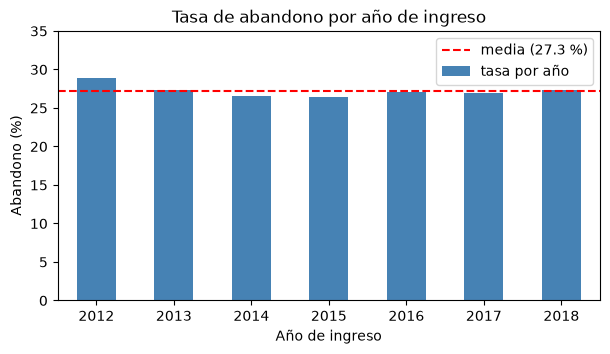

In [28]:
# gráfica: tasa de abandono por año, con la media como referencia
import matplotlib.pyplot as plt

ax = tasa_abandono.plot(kind='bar', color='steelblue', figsize=(7, 3.5), rot=0, label='tasa por año')
ax.axhline(y.mean() * 100, color='red', linestyle='--', label=f'media ({y.mean() * 100:.1f} %)')
ax.set_ylim(0, 35)
ax.set_xlabel('Año de ingreso')
ax.set_ylabel('Abandono (%)')
ax.set_title('Tasa de abandono por año de ingreso')
ax.legend()
plt.show()

#### Conclusión del 2.2.2

La tasa de abandono no cambia mucho entre años: va del 26,4 % (2015) al 28,9 % (2012), así que es estable, como se ve en la gráfica. 2018 tiene un 27,3 %, igual que la media, por lo que apartarlo como prueba no desequilibra las clases.

### 2.2.3 División por años

Se aparta el año más reciente (2018) como conjunto de prueba y se entrena con 2012-2017.

In [29]:
# 2.2.3 División por años: 2018 como prueba, 2012-2017 como entrenamiento
es_2018 = anio == 2018   # True si el alumno es de 2018

X_train, y_train = X[~es_2018], y[~es_2018]   # años 2012-2017
X_test,  y_test  = X[es_2018],  y[es_2018]    # año 2018

print('Entrenamiento:', X_train.shape, '| abandono:', round(y_train.mean() * 100, 1), '%')
print('Prueba:       ', X_test.shape,  '| abandono:', round(y_test.mean() * 100, 1), '%')


Entrenamiento: (31426, 26) | abandono: 27.3 %
Prueba:        (5289, 26) | abandono: 27.3 %


#### Conclusión del 2.2.3

Se aparta el año 2018 como conjunto de prueba y se entrena con 2012-2017. No se usa un 30 % al azar porque el test de Kaggle son años posteriores (2019 y 2020), y la prueba tiene que imitar esa situación: entrenar con años pasados y evaluar con un año que el modelo no ha visto.

Se elige 2018 porque es el año más reciente y el más parecido al test. Además tiene 5.289 alumnos, suficientes para medir bien, y el entrenamiento se queda con 31.426. La tasa de abandono es del 27,3 % en las dos partes, así que la división no desequilibra las clases.

Este conjunto de prueba no se usará para elegir modelos, solo para evaluar el modelo final una vez.

### 2.3 Esquema de validación cruzada

Antes de comparar los modelos hay que decidir cómo se hace la validación cruzada sobre los datos de entrenamiento (2012-2017). Para elegir, se evalúa el mismo modelo, el mejor árbol de la práctica 1, de dos maneras:

- **Aleatoria (StratifiedKFold):** reparte los alumnos al azar en 5 partes, como en la práctica 1. Cada parte mezcla alumnos de todos los años.
- **Por años (GroupKFold):** cada año es un grupo. En cada una de las 6 vueltas se entrena con 5 años y se valida con el que queda, así el modelo siempre se evalúa con un año que no ha visto, igual que en Kaggle.

Si el F1 por años saliera mucho más bajo, significaría que la validación aleatoria era demasiado optimista.

In [30]:
# 2.3 Esquema de validación cruzada: aleatoria vs. por años
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_score
from sklearn.base import clone

anio_train = anio[~es_2018]   # año de cada alumno de X_train (2012-2017)

# modelo de referencia: el mejor árbol de la práctica 1
arbol = clone(pipeline).set_params(modelo__max_depth=10, modelo__class_weight='balanced')

# a) aleatoria, como en la práctica 1
cv_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_azar = cross_val_score(arbol, X_train, y_train, cv=cv_azar, scoring='f1')

# b) por años: 6 años -> 6 vueltas, cada vuelta valida con un año entero que no ha visto
cv_anios = GroupKFold(n_splits=6)
f1_anios = cross_val_score(arbol, X_train, y_train, cv=cv_anios, groups=anio_train, scoring='f1')

print('F1 aleatoria:', f1_azar.round(3), '-> media', f1_azar.mean().round(3))
print('F1 por años: ', f1_anios.round(3), '-> media', f1_anios.mean().round(3))


F1 aleatoria: [0.536 0.536 0.529 0.533 0.528] -> media 0.532
F1 por años:  [0.542 0.538 0.537 0.52  0.547 0.516] -> media 0.533


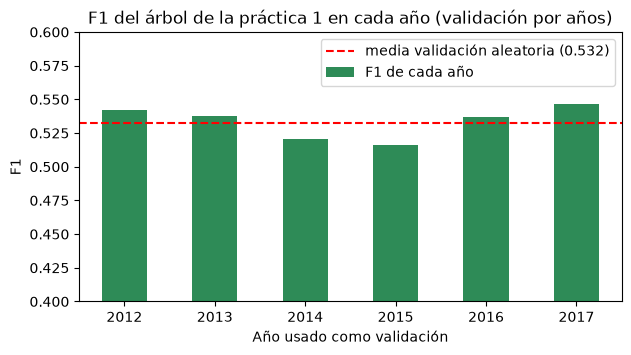

In [31]:
# gráfica: F1 de cada año en la validación por años, frente a la media de la validación aleatoria
anio_validado = [anio_train.iloc[val].iloc[0] for _, val in cv_anios.split(X_train, y_train, groups=anio_train)]
f1_por_anio = pd.Series(f1_anios, index=anio_validado).sort_index()

ax = f1_por_anio.plot(kind='bar', color='seagreen', figsize=(7, 3.5), rot=0, label='F1 de cada año')
ax.axhline(f1_azar.mean(), color='red', linestyle='--', label=f'media validación aleatoria ({f1_azar.mean():.3f})')
ax.set_ylim(0.4, 0.6)
ax.set_xlabel('Año usado como validación')
ax.set_ylabel('F1')
ax.set_title('F1 del árbol de la práctica 1 en cada año (validación por años)')
ax.legend()
plt.show()

#### Conclusión del 2.3

Las dos formas dan casi el mismo F1: 0,532 con la validación aleatoria y 0,533 por años. En la gráfica se ve que el F1 de cada año va de 0,516 (2015) a 0,547 (2017), alrededor de la media aleatoria, así que el modelo funciona parecido en todos los años. Los datos no cambian mucho con el tiempo, en parte porque en la práctica 1 ya se corrigió el cambio de meses_matriculado en 2018 con proporcion_periodo.

Aun así, a partir de aquí se usa la validación por años (GroupKFold con el año como grupo), porque imita mejor cómo es el test de Kaggle y cuesta lo mismo. Tiene una limitación: en algunas vueltas se entrena con años posteriores al que se valida (por ejemplo, para validar 2013 se usa 2014-2017). La alternativa que siempre mira hacia delante sería TimeSeriesSplit, pero con ella las primeras vueltas entrenarían con muy pocos años.

## 3. Modelos de clasificación

Se comparan los 9 modelos del material de la práctica, primero con su configuración por defecto. En la sección 4 se evalúan todos con la misma validación por años, y en la sección 5 se ajustan los hiperparámetros de los mejores.

| Modelo | Cómo funciona (resumen) | Hiperparámetros principales |
|---|---|---|
| kNN | Mira los k alumnos más parecidos y predice la clase que más se repite entre ellos | n_neighbors, weights |
| Naive Bayes | Calcula la probabilidad de cada clase suponiendo que las variables son independientes entre sí | var_smoothing |
| Árbol de decisión | Hace preguntas sucesivas sobre las variables hasta llegar a una hoja con la clase | max_depth, min_samples_leaf, class_weight |
| Bagging | Entrena muchos árboles con muestras al azar de los datos y vota | n_estimators, max_samples |
| Random Forest | Como Bagging, pero cada corte del árbol solo mira algunas variables al azar | n_estimators, max_depth, max_features, class_weight |
| AdaBoost | Entrena árboles muy simples uno tras otro; cada uno se fija en los alumnos que fallaron los anteriores | n_estimators, learning_rate |
| Gradient Boosting | Entrena árboles uno tras otro; cada uno corrige el error que dejan los anteriores | n_estimators, learning_rate, max_depth |
| Hist Gradient Boosting | Igual que Gradient Boosting, pero agrupa los valores en intervalos y es mucho más rápido | max_iter, learning_rate, max_leaf_nodes, class_weight |
| Regresión logística | Modelo lineal que da la probabilidad de abandono a partir de una suma ponderada de las variables | C, class_weight |

Bagging, Random Forest, AdaBoost y los dos Gradient Boosting son **ensembles**: combinan muchos modelos simples para obtener uno más fiable.


In [32]:
# 3. Modelos a comparar (configuración por defecto, como en el material)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.linear_model import LogisticRegression

random_state = 42   # misma semilla en todos para que los resultados se puedan repetir

modelos = {
    'kNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'Árbol de decisión': DecisionTreeClassifier(random_state=random_state),
    'Bagging': BaggingClassifier(random_state=random_state),
    'Random Forest': RandomForestClassifier(random_state=random_state),
    'AdaBoost': AdaBoostClassifier(random_state=random_state),
    'Gradient Boosting': GradientBoostingClassifier(random_state=random_state),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=random_state),
    'Regresión logística': LogisticRegression(max_iter=5000, random_state=random_state),
}

print(len(modelos), 'modelos:', list(modelos))


9 modelos: ['kNN', 'Naive Bayes', 'Árbol de decisión', 'Bagging', 'Random Forest', 'AdaBoost', 'Gradient Boosting', 'Hist Gradient Boosting', 'Regresión logística']


## 4. Evaluación de los modelos por defecto

Se evalúan los 9 modelos con su configuración por defecto, usando el mismo pipeline y la misma validación por años (`cv_anios`). Además del F1, que es la métrica de Kaggle, se miran la precisión, el recall y el accuracy para entender cómo se equivoca cada modelo.

In [33]:
# 4. Evaluación base: los 9 modelos con la validación por años
import time
from sklearn.model_selection import cross_validate

metricas = ['f1', 'precision', 'recall', 'accuracy']
sin_texto_disperso = ['Naive Bayes', 'Hist Gradient Boosting']   # no aceptan matrices dispersas

# mismo preprocesado, pero devolviendo una tabla normal (densa) para esos dos modelos
preprocesado_denso = ColumnTransformer(preprocesado.transformers, sparse_threshold=0)

resultados_base = {}
for nombre, modelo in modelos.items():
    if nombre in sin_texto_disperso:
        prep = preprocesado_denso
    else:
        prep = preprocesado

    # pipeline completo para este modelo: limpieza -> preprocesado -> modelo
    pipe = Pipeline([
        ('limpiar', limpieza),
        ('preprocesado', prep),
        ('modelo', modelo)
    ])

    inicio = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv_anios, groups=anio_train,
                       scoring=metricas, n_jobs=-1)
    resultados_base[nombre] = {
        'f1': r['test_f1'].mean(),
        'f1_desv': r['test_f1'].std(),
        'precision': r['test_precision'].mean(),
        'recall': r['test_recall'].mean(),
        'accuracy': r['test_accuracy'].mean(),
        'segundos': time.time() - inicio,
    }
    print(f'{nombre}: F1 = {resultados_base[nombre]["f1"]:.3f}')

tabla_base = pd.DataFrame(resultados_base).T.sort_values('f1', ascending=False).round(3)
tabla_base


kNN: F1 = 0.379
Naive Bayes: F1 = 0.520
Árbol de decisión: F1 = 0.445
Bagging: F1 = 0.454
Random Forest: F1 = 0.466
AdaBoost: F1 = 0.444
Gradient Boosting: F1 = 0.480
Hist Gradient Boosting: F1 = 0.552
Regresión logística: F1 = 0.555


,f1,f1_desv,precision,recall,accuracy,segundos
Regresión logística,0.555,0.016,0.677,0.471,0.795,1.485
Hist Gradient Boosting,0.552,0.013,0.688,0.461,0.797,14.367
Naive Bayes,0.520,0.017,0.399,0.751,0.622,3.495
Gradient Boosting,0.480,0.021,0.729,0.358,0.789,4.447
Random Forest,0.466,0.018,0.729,0.342,0.786,11.269
Bagging,0.454,0.011,0.633,0.355,0.768,12.365
Árbol de decisión,0.445,0.011,0.445,0.445,0.698,2.955
AdaBoost,0.444,0.014,0.658,0.335,0.771,1.358
kNN,0.379,0.014,0.547,0.290,0.741,9.253


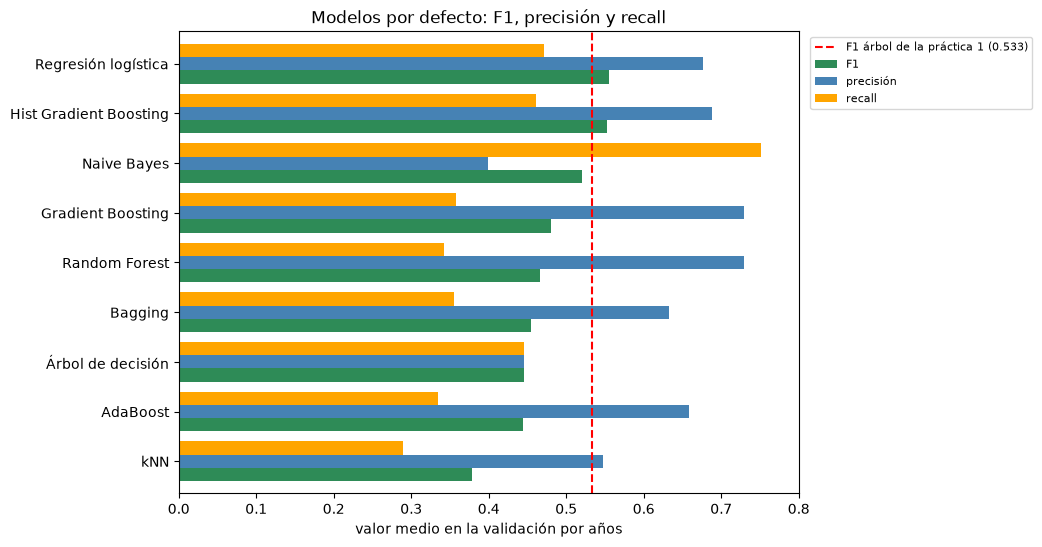

In [34]:
# Gráfica: F1, precisión y recall de cada modelo (validación por años)
import matplotlib.pyplot as plt

# orden de menor a mayor F1 para que el mejor quede arriba en las barras horizontales
datos_grafica = tabla_base[['f1', 'precision', 'recall']].sort_values('f1')
datos_grafica.columns = ['F1', 'precisión', 'recall']

ax = datos_grafica.plot(kind='barh', color=['seagreen', 'steelblue', 'orange'],
                        figsize=(8, 6), width=0.8)
ax.axvline(f1_anios.mean(), color='red', linestyle='--',
           label=f'F1 árbol de la práctica 1 ({f1_anios.mean():.3f})')

ax.set_xlim(0, 0.8)
ax.set_xlabel('valor medio en la validación por años')
ax.set_title('Modelos por defecto: F1, precisión y recall')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)   # leyenda fuera para no tapar barras
plt.show()

#### Conclusión de la sección 4

Con la configuración por defecto, los mejores modelos son la regresión logística (F1 0,555) e Hist Gradient Boosting (0,552). Los dos ya superan al árbol ajustado de la práctica 1 (0,533 con la misma validación por años). Les siguen Naive Bayes (0,520) y Gradient Boosting (0,480). Los peores son AdaBoost (0,444) y kNN (0,379). La desviación entre años es pequeña en todos (entre 0,011 y 0,021), así que el orden es fiable.

En la gráfica se ve que casi todos los modelos tienen precisión alta (barra azul) y recall bajo (barra naranja). Por ejemplo, Random Forest acierta el 73 % de las veces que dice "abandona", pero solo detecta al 34 % de los que abandonan. Naive Bayes hace lo contrario: detecta al 75 % pero se equivoca mucho (precisión 0,40). Como el F1 necesita las dos cosas, el margen de mejora está en equilibrarlas, por ejemplo con class_weight='balanced', que ningún modelo usa por defecto.

El árbol de decisión sin límite tiene precisión y recall iguales (0,445), porque crece hasta memorizar el entrenamiento. Bagging y Random Forest, que combinan muchos árboles así, mejoran algo el F1, pero siguen detectando pocos abandonos.

Para la sección 5 se eligen la regresión logística e Hist Gradient Boosting, por ser los mejores, y Random Forest y Gradient Boosting, porque tienen precisión alta y pueden mejorar mucho al equilibrar las clases.


## 5. Selección de hiperparámetros

Se ajustan los hiperparámetros de los cuatro modelos elegidos en la sección 4 con `GridSearchCV`, siempre sobre el pipeline completo (limpieza, preprocesado y modelo) y con la misma validación por años. Las rejillas son pequeñas a propósito, porque cada combinación se entrena 6 veces (una por año) y los modelos de árboles tardan mucho.

### 5.1 Función auxiliar

La función `buscar` hace lo mismo que `optimize_with_grid_search` del material: monta el pipeline con el modelo, lanza `GridSearchCV` con la validación por años y muestra las mejores combinaciones. Se añade el F1 de entrenamiento (`return_train_score=True`) para ver si el modelo sobreajusta.

In [35]:
# 5.1 Función auxiliar: GridSearchCV sobre el pipeline completo con la validación por años
from sklearn.model_selection import GridSearchCV

def buscar(modelo, rejilla, denso=False, n_jobs=-1):
    if denso:
        prep = preprocesado_denso   # para modelos que no aceptan matrices dispersas (sección 4)
    else:
        prep = preprocesado

    pipe = Pipeline([
        ('limpiar', limpieza),
        ('preprocesado', prep),
        ('modelo', modelo)
    ])

    # n_jobs: cuántas combinaciones se entrenan a la vez (-1 = todos los núcleos)
    busqueda = GridSearchCV(pipe, rejilla, cv=cv_anios, scoring='f1',
                            n_jobs=n_jobs, return_train_score=True)
    inicio = time.time()
    busqueda.fit(X_train, y_train, groups=anio_train)   # groups: el año de cada alumno

    print(f'Tiempo: {time.time() - inicio:.0f} s')
    print('Mejores parámetros:', busqueda.best_params_)
    print(f'Mejor F1 (validación por años): {busqueda.best_score_:.3f}')

    # las 5 mejores combinaciones, con el F1 en entrenamiento para ver si sobreajusta
    tabla = pd.DataFrame(busqueda.cv_results_).sort_values('rank_test_score')
    columnas = ['params', 'mean_test_score', 'std_test_score', 'mean_train_score']
    display(tabla[columnas].head(5).round(3))
    return busqueda


### 5.2 Regresión logística

In [36]:
# 5.2 Regresión logística: fuerza de la regularización (C) y pesos de las clases
rejilla_lr = {
    'modelo__C': [0.01, 0.1, 1, 10],                # 1 es el valor por defecto
    'modelo__class_weight': [None, 'balanced'],
}
busqueda_lr = buscar(modelos['Regresión logística'], rejilla_lr)


Tiempo: 6 s
Mejores parámetros: {'modelo__C': 0.1, 'modelo__class_weight': 'balanced'}
Mejor F1 (validación por años): 0.614


,params,mean_test_score,std_test_score,mean_train_score
3,"{'modelo__C': 0.1, 'modelo__class_weight': 'ba...",0.614,0.005,0.629
5,"{'modelo__C': 1, 'modelo__class_weight': 'bala...",0.612,0.006,0.631
7,"{'modelo__C': 10, 'modelo__class_weight': 'bal...",0.611,0.006,0.632
1,"{'modelo__C': 0.01, 'modelo__class_weight': 'b...",0.605,0.005,0.613
6,"{'modelo__C': 10, 'modelo__class_weight': None}",0.555,0.015,0.581


#### Conclusión del 5.2

La mejor combinación es C=0.1 con class_weight='balanced', con F1 **0,614**, frente a 0,555 por defecto. La mejora viene sobre todo de equilibrar las clases: el modelo deja de favorecer la clase mayoritaria (no abandona) y detecta más abandonos. Un C más pequeño que el de por defecto (1) significa más regularización, es decir, un modelo más sencillo que no se fía tanto de cada palabra de los comentarios.

El F1 de entrenamiento (0,629) es casi igual al de validación, así que el modelo no sobreajusta.

### 5.3 Hist Gradient Boosting

In [37]:
# 5.3 Hist Gradient Boosting
# Rejilla mínima por coste computacional: cada entrenamiento ya es lento y usa todos los núcleos.
# Se prueba solo el cambio que más mejoró a la regresión logística: class_weight='balanced'.
rejilla_hgb = {'modelo__class_weight': ['balanced']}

# n_jobs=1: el modelo ya usa todos los núcleos por dentro
busqueda_hgb = buscar(modelos['Hist Gradient Boosting'], rejilla_hgb, denso=True, n_jobs=1)


Tiempo: 26 s
Mejores parámetros: {'modelo__class_weight': 'balanced'}
Mejor F1 (validación por años): 0.612


,params,mean_test_score,std_test_score,mean_train_score
0,{'modelo__class_weight': 'balanced'},0.612,0.006,0.664


#### Conclusión del 5.3

Solo con class_weight='balanced', Hist Gradient Boosting pasa de 0,552 a **0,612**, prácticamente lo mismo que la regresión logística (0,614). No se probaron más hiperparámetros (learning_rate, max_iter, max_leaf_nodes) por el coste computacional: cada entrenamiento usa ya todos los núcleos del ordenador.

El F1 de entrenamiento (0,664) es algo mayor que el de validación, así que sobreajusta un poco más que la regresión logística, aunque la diferencia es pequeña.

### 5.4 Random Forest

In [38]:
# 5.4 Random Forest
# class_weight fijo en 'balanced' (decisivo en 5.2 y 5.3); se ajusta el tamaño de los árboles
rejilla_rf = {
    'modelo__max_depth': [20, None],               # None = sin límite (por defecto)
    'modelo__min_samples_leaf': [1, 5],            # mínimo de alumnos por hoja; 1 por defecto
    'modelo__class_weight': ['balanced'],
}
# n_jobs=4: 4 entrenamientos a la vez, para limitar el uso de memoria
busqueda_rf = buscar(modelos['Random Forest'], rejilla_rf, n_jobs=4)


Tiempo: 38 s
Mejores parámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}
Mejor F1 (validación por años): 0.597


,params,mean_test_score,std_test_score,mean_train_score
3,"{'modelo__class_weight': 'balanced', 'modelo__...",0.597,0.006,0.724
1,"{'modelo__class_weight': 'balanced', 'modelo__...",0.595,0.007,0.662
0,"{'modelo__class_weight': 'balanced', 'modelo__...",0.593,0.008,0.761
2,"{'modelo__class_weight': 'balanced', 'modelo__...",0.573,0.007,1.000


#### Conclusión del 5.4

La mejor combinación es max_depth=None con min_samples_leaf=5 y class_weight='balanced', con F1 **0,597**, frente a 0,466 por defecto. Es el modelo que más mejora: por defecto detectaba pocos abandonos (recall 0,34) y al equilibrar las clases los detecta mucho mejor.

Pedir al menos 5 alumnos por hoja evita que los árboles memoricen casos sueltos. Aun así, el F1 de entrenamiento (0,724) queda bastante por encima del de validación, así que es el que más sobreajusta de los tres y sigue por debajo de la regresión logística y de Hist Gradient Boosting.

### 5.5 Gradient Boosting

In [39]:
# 5.5 Gradient Boosting
# GradientBoostingClassifier no tiene class_weight: se ajustan la tasa de aprendizaje y el número de árboles
rejilla_gb = {
    'modelo__learning_rate': [0.1, 0.2],           # 0.1 por defecto
    'modelo__n_estimators': [100, 300],            # 100 por defecto
}
# n_jobs=4: 4 entrenamientos a la vez, para limitar el uso de memoria
busqueda_gb = buscar(modelos['Gradient Boosting'], rejilla_gb, n_jobs=4)


Tiempo: 61 s
Mejores parámetros: {'modelo__learning_rate': 0.2, 'modelo__n_estimators': 300}
Mejor F1 (validación por años): 0.556


,params,mean_test_score,std_test_score,mean_train_score
3,"{'modelo__learning_rate': 0.2, 'modelo__n_esti...",0.556,0.014,0.644
1,"{'modelo__learning_rate': 0.1, 'modelo__n_esti...",0.544,0.017,0.598
2,"{'modelo__learning_rate': 0.2, 'modelo__n_esti...",0.525,0.015,0.573
0,"{'modelo__learning_rate': 0.1, 'modelo__n_esti...",0.480,0.021,0.514


#### Conclusión del 5.5

La mejor combinación es learning_rate=0.2 con n_estimators=300, con F1 **0,556**, frente a 0,480 por defecto. Más árboles y una tasa de aprendizaje mayor ayudan, porque el modelo por defecto se queda corto: su F1 de entrenamiento (0,514) es casi igual al de validación. Con 300 árboles el F1 de entrenamiento sube a 0,644, así que empieza a sobreajustar.

Aun así, queda lejos de los otros tres (entre 0,597 y 0,614). Este modelo no tiene class_weight, así que no se pueden equilibrar las clases, que fue la mejora decisiva en los demás. Además, es el más lento (65 s con solo 4 combinaciones), por eso no se amplía la rejilla.

### 5.6 Comparación de los modelos ajustados

Se juntan en una tabla los resultados de la sección 4 (configuración por defecto) y los de las búsquedas del 5.2 al 5.5, para ver cuánto mejora cada modelo y cuál es el mejor. También se incluye el F1 de entrenamiento y la desviación entre años de la mejor combinación.

In [40]:
# 5.6 Tabla resumen: por defecto (sección 4) frente a ajustado (GridSearchCV)
busquedas = {
    'Regresión logística': busqueda_lr,
    'Hist Gradient Boosting': busqueda_hgb,
    'Random Forest': busqueda_rf,
    'Gradient Boosting': busqueda_gb,
}

filas = {}
for nombre, busqueda in busquedas.items():
    mejor = busqueda.best_index_   # fila de cv_results_ con la mejor combinación
    filas[nombre] = {
        'F1 por defecto': tabla_base.loc[nombre, 'f1'],
        'F1 ajustado': busqueda.best_score_,
        'mejora': busqueda.best_score_ - tabla_base.loc[nombre, 'f1'],
        'desviación': busqueda.cv_results_['std_test_score'][mejor],
        'F1 entrenamiento': busqueda.cv_results_['mean_train_score'][mejor],
        # quitar el prefijo 'modelo__' para que se lea mejor
        'mejores parámetros': {k.replace('modelo__', ''): v for k, v in busqueda.best_params_.items()},
    }

tabla_ajuste = pd.DataFrame.from_dict(filas, orient='index').sort_values('F1 ajustado', ascending=False)
tabla_ajuste.round(3)

,F1 por defecto,F1 ajustado,mejora,desviación,F1 entrenamiento,mejores parámetros
Regresión logística,0.555,0.614,0.059,0.005,0.629,"{'C': 0.1, 'class_weight': 'balanced'}"
Hist Gradient Boosting,0.552,0.612,0.060,0.006,0.664,{'class_weight': 'balanced'}
Random Forest,0.466,0.597,0.131,0.006,0.724,"{'class_weight': 'balanced', 'max_depth': None..."
Gradient Boosting,0.480,0.556,0.076,0.014,0.644,"{'learning_rate': 0.2, 'n_estimators': 300}"


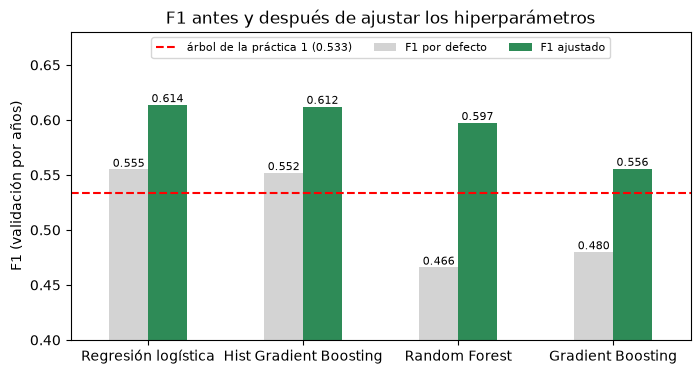

In [41]:
# Gráfica: F1 por defecto frente a F1 ajustado de cada modelo
import matplotlib.pyplot as plt

ax = tabla_ajuste[['F1 por defecto', 'F1 ajustado']].plot(
    kind='bar', color=['lightgray', 'seagreen'], figsize=(8, 4), rot=0)
ax.axhline(f1_anios.mean(), color='red', linestyle='--',
           label=f'árbol de la práctica 1 ({f1_anios.mean():.3f})')

# escribir el valor encima de cada barra
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.3f', fontsize=8)

ax.set_ylim(0.4, 0.68)
ax.set_ylabel('F1 (validación por años)')
ax.set_title('F1 antes y después de ajustar los hiperparámetros')
ax.legend(loc='upper center', ncol=3, fontsize=8)
plt.show()

#### Conclusión del 5.6

Los cuatro modelos mejoran al ajustar los hiperparámetros, y todos superan al árbol de la práctica 1 (0,533). La mayor mejora es la de Random Forest (+0,131, de 0,466 a 0,597), seguida de Gradient Boosting (+0,076), Hist Gradient Boosting (+0,060) y regresión logística (+0,059). En los tres primeros el cambio decisivo es class_weight='balanced'. Gradient Boosting no tiene ese parámetro y es el que se queda más atrás (0,556).

Los dos mejores son la **regresión logística (0,614)** e **Hist Gradient Boosting (0,612)**. La diferencia entre ellos (0,002) es menor que su desviación entre años (0,005-0,006), así que en la práctica rinden igual. Aun así, la regresión logística tiene tres ventajas:
- Sobreajusta menos: F1 de entrenamiento 0,629 frente a 0,664.
- Es mucho más rápida: 6 s para 8 combinaciones, frente a 24 s para una sola.
- Es más fácil de interpretar, porque cada variable tiene un coeficiente.

Por eso, de momento, la regresión logística es la candidata a modelo final. Antes de elegirlo definitivamente queda probar el modelo extra y las mejoras en las variables.